# Deteksi Pneumonia menggunakan ekstraksi fitur GLCM dengan menggabungkan 3 algoritma klasik Random Forest , SVM dan KNN

---
# Install Depedensi

In [ ]:
%pip install opencv-python scikit-image scikit-learn pandas numpy matplotlib joblib 

   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---- ----------------------------------- 4.7/44.0 MB 23.4 MB/s eta 0:00:02
   -------- ------------------------------- 9.4/44.0 MB 24.2 MB/s eta 0:00:02
   ------------ --------------------------- 14.2/44.0 MB 23.0 MB/s eta 0:00:02
   ---------------- ----------------------- 18.4/44.0 MB 22.7 MB/s eta 0:00:02
   --------------------- ------------------ 23.3/44.0 MB 22.5 MB/s eta 0:00:01
   ------------------------- -------------- 27.8/44.0 MB 22.5 MB/s eta 0:00:01
   ----------------------------- ---------- 32.2/44.0 MB 22.5 MB/s eta 0:00:01
   --------------------------------- ------ 37.0/44.0 MB 22.6 MB/s eta 0:00:01
   -------------------------------------- - 41.9/44.0 MB 22.6 MB/s eta 0:00:01
   ---------------------------------------- 44.0/44.0 MB 22.1 MB/s  0:00:01
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   --------------- ------------------------ 4.7/12.0 MB 23.1 MB/s eta 0:00:

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


---
# Import Library

In [2]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library khusus Ekstraksi Fitur GLCM
from skimage.feature import graycomatrix, graycoprops

# Library 3 Algoritma Klasifikasi
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Library Preprocessing & Evaluasi Model
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Library untuk menyimpan model (.pkl / .joblib)
import joblib

print("Semua library berhasil di-import dan siap digunakan!")

Semua library berhasil di-import dan siap digunakan!


# Penjelasan Singkat Fungsi Library:
### cv2 (OpenCV) & os: Membaca file gambar dari folder laptop dan mengubah ukurannya (resize).

### graycomatrix & graycoprops: Fungsi inti untuk menghitung matriks GLCM dan mengambil fitur tekstur (Contrast, Homogeneity, dll).

### SVC, RandomForestClassifier, KNeighborsClassifier: Tiga algoritma pembanding yang akan ditraining.

### StandardScaler: Mengubah skala nilai fitur GLCM agar seimbang sebelum masuk ke model ML.

### joblib: Meng-export model yang sudah pintar menjadi file fisik agar nanti bisa dipanggil oleh Streamlit.

---
# Loading Path & Pembacaan Struktur Dataset.

In [5]:
import os
import pandas as pd

# 1. Tentukan lokasi folder utama dataset (sesuaikan dengan lokasi ekstrak di laptopmu)
DATASET_DIR = "archive/chest_xray"  # Contoh: jika foldernya sejajar dengan file script

def load_dataset_paths(base_dir):
    file_paths = []
    labels = []
    splits = ['train', 'val', 'test']
    
    for split in splits:
        split_dir = os.path.join(base_dir, split)
        
        # Cek jika folder split ada
        if not os.path.exists(split_dir):
            print(f"Warning: Folder {split_dir} tidak ditemukan!")
            continue
            
        for label_name in ['NORMAL', 'PNEUMONIA']:
            class_dir = os.path.join(split_dir, label_name)
            if not os.path.exists(class_dir):
                continue
            
            # Konversi label string ke numerik: NORMAL = 0, PNEUMONIA = 1
            label_value = 0 if label_name == 'NORMAL' else 1
            
            for fname in os.listdir(class_dir):
                # Filter hanya mengambil file gambar (.jpeg / .jpg / .png)
                if fname.lower().endswith(('.jpeg', '.jpg', '.png')):
                    full_path = os.path.join(class_dir, fname)
                    file_paths.append(full_path)
                    labels.append(label_value)
                    
    # Buat DataFrame
    df = pd.DataFrame({
        'file_path': file_paths,
        'label': labels,
        'label_name': ['NORMAL' if l == 0 else 'PNEUMONIA' for l in labels]
    })
    
    return df

# 2. Eksekusi pembacaan dataset
df_dataset = load_dataset_paths(DATASET_DIR)

# 3. Tampilkan ringkasan data yang berhasil terbaca
print(f"Total gambar yang berhasil dimuat: {len(df_dataset)} file")
print("\nDistribusi Jumlah Kelas:")
print(df_dataset['label_name'].value_counts())

# Tampilkan 5 baris pertama tabel
print("\nSampel 5 Data Pertama:")
print(df_dataset.head())

Total gambar yang berhasil dimuat: 5856 file

Distribusi Jumlah Kelas:
label_name
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64

Sampel 5 Data Pertama:
                                           file_path  label label_name
0  archive/chest_xray\train\NORMAL\IM-0115-0001.jpeg      0     NORMAL
1  archive/chest_xray\train\NORMAL\IM-0117-0001.jpeg      0     NORMAL
2  archive/chest_xray\train\NORMAL\IM-0119-0001.jpeg      0     NORMAL
3  archive/chest_xray\train\NORMAL\IM-0122-0001.jpeg      0     NORMAL
4  archive/chest_xray\train\NORMAL\IM-0125-0001.jpeg      0     NORMAL


---
# Penjelasan Kode 
### Rekursi Path: Kode menyusuri seluruh folder (train, val, test) dan subfolder kelas (NORMAL, PNEUMONIA) untuk mengambil lokasi file .jpeg.
### Label Encoding: Mengubah label teks menjadi bentuk numerik agar bisa dibaca model Machine Learning: 0 = NORMAL dan 1 = PNEUMONIA.
### Pandas DataFrame: Menggabungkan seluruh jalur file dan labelnya ke dalam satu tabel terstruktur (df_dataset).
---
# Penjelasan Hasil Output
### Total Data Pas: Terbaca 5.856 file, artinya seluruh dataset dari Kaggle sudah masuk tanpa ada file yang terlewat.
### Kondisi Data Imbalance (Tidak Seimbang):PNEUMONIA: 4.273 gambar (~73%)NORMAL: 1.583 gambar (~27%)
#### Catatan: Data mengalami imbalance. saat evaluasi model, patokannya jangan cuma Akurasi, tapi wajib lihat F1-Score dan Confusion Matrix 
# Sampel Data: 5 baris pertama menunjukkan file path yang siap dipanggil oleh OpenCV untuk ekstraksi fitur.

---

# Preprocessing Citra (Grayscale & Resize).

### membuat fungsi untuk mengubah seluruh gambar ke dalam format standar sebelum diproses oleh GLCM.

Ukuran asli gambar    : (1858, 2090, 3)
Ukuran hasil preprocess: (128, 128)


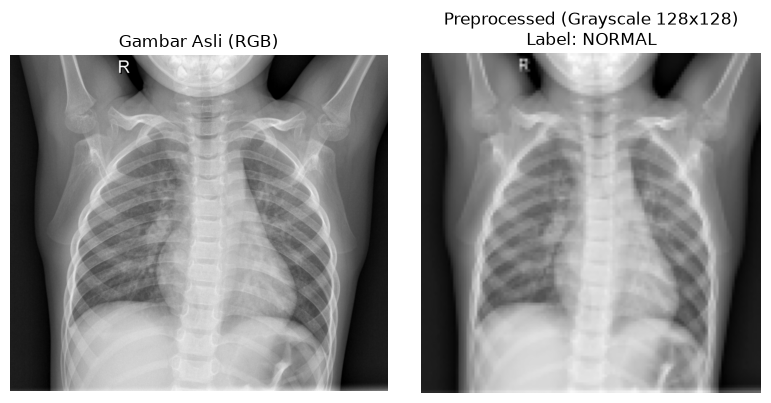

In [6]:
import cv2
import matplotlib.pyplot as plt

# Tentukan ukuran gambar standar (128x128 piksel adalah ukuran ideal untuk GLCM)
IMG_SIZE = (128, 128)

def preprocess_image(image_path, target_size=IMG_SIZE):
    # 1. Baca gambar dari path
    img = cv2.imread(image_path)
    
    if img is None:
        return None
    
    # 2. Konversi BGR/RGB ke Grayscale (derajat keabuan 0–255)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # 3. Ubah ukuran dimensi gambar menjadi 128x128 piksel
    resized = cv2.resize(gray, target_size, interpolation=cv2.INTER_AREA)
    
    return resized

# --- Pengujian pada 1 Gambar Sampel ---
sample_path = df_dataset['file_path'].iloc[0]
sample_label = df_dataset['label_name'].iloc[0]

# Jalankan fungsi preprocessing
processed_img = preprocess_image(sample_path)

# Tampilkan ukuran sebelum dan sesudah
img_original = cv2.imread(sample_path)
print(f"Ukuran asli gambar    : {img_original.shape}")
print(f"Ukuran hasil preprocess: {processed_img.shape}")

# Visualisasi perbandingan gambar
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB))
axes[0].set_title("Gambar Asli (RGB)")
axes[0].axis('off')

axes[1].imshow(processed_img, cmap='gray')
axes[1].set_title(f"Preprocessed (Grayscale 128x128)\nLabel: {sample_label}")
axes[1].axis('off')

plt.tight_layout()
plt.show()

# Penjelasan Detil Proses
### Konversi Grayscale: GLCM membutuhkan masukan matriks 1 channel dengan rentang nilai intensitas 0 (hitam) sampai 255 (putih) untuk menghitung persebaran pola piksel.
### Resize (128 X 128): Gambar asli bawaan Kaggle ukurannya sangat besar (bisa di atas 1.000 X 1.000 piksel). Mengubahnya ke 128 X 128 piksel akan mempercepat proses ekstraksi fitur GLCM secara drastis tanpa merusak tekstur khas paru-paru.
### cv2.INTER_AREA: Metode interpolation terbaik saat memperkecil gambar (downsampling) agar tidak memunculkan efek aliasing (garis bergelombang palsu).

---
# Ekstraksi Fitur GLCM (Gray-Level Co-occurrence Matrix).

In [7]:
import numpy as np
import pandas as pd
from skimage.feature import graycomatrix, graycoprops

# 1. Fungsi untuk mengekstrak fitur GLCM dari 1 citra grayscale
def extract_glcm_features(img):
    # Parameter GLCM: jarak 1 piksel dan 4 sudut (0°, 45°, 90°, 135° dalam radian)
    distances = [1]
    angles = [0, np.pi/4, np.pi/2, 3*np.pi/4]
    
    # Hitung matriks GLCM
    glcm = graycomatrix(img, distances=distances, angles=angles, levels=256, symmetric=True, normed=True)
    
    # Ekstraksi 6 properti fitur tekstur utama
    contrast = graycoprops(glcm, 'contrast').mean()
    dissimilarity = graycoprops(glcm, 'dissimilarity').mean()
    homogeneity = graycoprops(glcm, 'homogeneity').mean()
    energy = graycoprops(glcm, 'energy').mean()
    correlation = graycoprops(glcm, 'correlation').mean()
    asm = graycoprops(glcm, 'ASM').mean()
    
    return {
        'contrast': contrast,
        'dissimilarity': dissimilarity,
        'homogeneity': homogeneity,
        'energy': energy,
        'correlation': correlation,
        'asm': asm
    }

# 2. Proses ekstraksi seluruh gambar di df_dataset
features_list = []
total_images = len(df_dataset)

print("Mulai mengekstrak fitur GLCM untuk seluruh dataset...")

for idx, row in df_dataset.iterrows():
    img_path = row['file_path']
    img = preprocess_image(img_path)  # Memanggil fungsi preprocess dari Langkah 3
    
    if img is not None:
        feat = extract_glcm_features(img)
        features_list.append(feat)
    else:
        # Penanganan jika file gambar rusak
        features_list.append({
            'contrast': 0, 'dissimilarity': 0, 'homogeneity': 0,
            'energy': 0, 'correlation': 0, 'asm': 0
        })
        
    # Tampilkan indikator progress setiap 1000 gambar
    if (idx + 1) % 1000 == 0 or (idx + 1) == total_images:
        print(f"Progress: Selesai mengekstrak {idx + 1}/{total_images} gambar...")

# 3. Gabungkan hasil ekstraksi fitur ke DataFrame utama
df_glcm = pd.DataFrame(features_list)
df_final = pd.concat([df_dataset, df_glcm], axis=1)

print("\nEkstraksi fitur GLCM selesai!")
print(f"Dimensi dataset hasil ekstraksi: {df_final.shape}")

# Tampilkan 5 sampel data pertama hasil ekstraksi
print("\nSampel 5 Baris Fitur GLCM:")
print(df_final[['label_name', 'contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'asm']].head())

Mulai mengekstrak fitur GLCM untuk seluruh dataset...
Progress: Selesai mengekstrak 1000/5856 gambar...
Progress: Selesai mengekstrak 2000/5856 gambar...
Progress: Selesai mengekstrak 3000/5856 gambar...
Progress: Selesai mengekstrak 4000/5856 gambar...
Progress: Selesai mengekstrak 5000/5856 gambar...
Progress: Selesai mengekstrak 5856/5856 gambar...

Ekstraksi fitur GLCM selesai!
Dimensi dataset hasil ekstraksi: (5856, 9)

Sampel 5 Baris Fitur GLCM:
  label_name    contrast  dissimilarity  homogeneity    energy  correlation  \
0     NORMAL  161.092109       7.966795     0.195151  0.019638     0.978613   
1     NORMAL  212.917542       9.084618     0.197189  0.061613     0.969256   
2     NORMAL  154.305351       7.622512     0.245403  0.088969     0.983295   
3     NORMAL  127.277443       6.963191     0.222776  0.022832     0.984489   
4     NORMAL  254.026645       9.521377     0.225751  0.103000     0.969048   

        asm  
0  0.000393  
1  0.003821  
2  0.007944  
3  0.000532  

### Penjelasan Kode Singkat

1. **`extract_glcm_features(img)`**: Mengambil gambar $128 \times 128$, menghitung hubungan spasial antar piksel bertetangga pada 4 arah sudut ($0^\circ, 45^\circ, 90^\circ, 135^\circ$), lalu mengambil nilai rata-ratanya (*mean*).
2. **Looping `df_dataset`**: Mengolah seluruh 5.856 gambar rontgen satu per satu secara otomatis.
3. **`pd.concat`**: Menggabungkan kolom nama file, label (`0` atau `1`), dan 6 kolom fitur GLCM numerik ke dalam satu tabel terstruktur (`df_final`).

---

### Penjelasan Detail (Materi & Karakteristik Fitur GLCM)

Dalam klasifikasi citra rontgen dada, penyakit Pneumonia menyebabkan adanya cairan/konsolidasi pada paru-paru yang mengubah tekstur serat keabuan gambar. GLCM menangkap perubahan tekstur ini melalui 6 nilai statistik:

1. **Contrast (Kontras):** Mengukur tingkat variasi/perbedaan intensitas lokal antara piksel dan tetangganya. Paru-paru berserabut atau terkena pneumonia cenderung memiliki nilai kontras tekstur yang lebih tinggi dibanding paru-paru normal yang mulus.
2. **Dissimilarity (Ketidaksamaan):** Serupa dengan kontras, tetapi meningkat secara linier seiring besarnya perbedaan nilai keabuan antar piksel.
3. **Homogeneity (Keseragaman):** Mengukur kehalusan dan homogenitas tekstur citra. Citra paru-paru normal tanpa bercak kotor umumnya memiliki nilai homogenitas yang lebih tinggi.
4. **Energy (Energi):** Mengukur kepencapaian keseragaman pasangan piksel. Nilai energi semakin besar jika distribusi derajat keabuan dalam citra sangat teratur/seragam.
5. **Correlation (Korelasi):** Mengukur keterikatan linier nilai derajat keabuan antar piksel tetangga di sepanjang matriks.
6. **ASM (Angular Second Moment):** Mengukur tingkat keteraturan tekstur (kuadrat dari nilai *Energy*).


---
**Langkah 5: Pembentukan Dataset Fitur ($X$ & $y$) dan Menyimpan Hasil ke CSV**.

Memisahkan tabel hasil ekstraksi GLCM menjadi **Matriks Fitur ($X$)** dan **Target Label ($y$)**. Selain itu,  menyimpan seluruh data fitur tersebut ke file `.csv` supaya jika VS Code tertutup atau kernel di-*restart*, tidak perlu mengulang proses ekstraksi gambar dari Langkah 4 yang makan waktu lama.


In [ ]:
import pandas as pd

# 1. Tentukan kolom-kolom fitur GLCM yang akan digunakan
feature_columns = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'asm']

# 2. Separasi matriks fitur (X) dan target label (y)
X = df_final[feature_columns]
y = df_final['label']

# 3. Simpan DataFrame lengkap ke file CSV sebagai backup
CSV_FILE_PATH = "glcm_features_pneumonia.csv"
df_final.to_csv(CSV_FILE_PATH, index=False)

print(f"Berhasil! Dataset fitur GLCM telah disimpan ke '{CSV_FILE_PATH}'")

# 4. Tampilkan informasi bentuk (shape) data $X$ dan $y$
print("\n--- Ringkasan Dataset Siap Latih ---")
print(f"Matriks Fitur (X) : {X.shape}  (5.856 gambar, 6 fitur GLCM)")
print(f"Vektor Label (y)  : {y.shape}  (5.856 target label)")

print("\nDistribusi Kelas Target (y):")
print(y.value_counts().rename({0: '0 (NORMAL)', 1: '1 (PNEUMONIA)'}))

print("\n5 Baris Pertama Matriks Fitur (X):")
print(X.head())

# --- CATATAN UNTUK MEMBACA KEMBALI FILE CSV (JIKA VSCODE DI-RESTART) ---
# Jika di lain waktu buka ulang notebook ini tanpa mau mengekstrak gambar lagi, 
# cukup jalankan 3 baris kode di bawah ini:
# df_loaded = pd.read_csv("glcm_features_pneumonia.csv")
# X = df_loaded[['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'asm']]
# y = df_loaded['label']

Berhasil! Dataset fitur GLCM telah disimpan ke 'glcm_features_pneumonia.csv'

--- Ringkasan Dataset Siap Latih ---
Matriks Fitur (X) : (5856, 6)  (5.856 gambar, 6 fitur GLCM)
Vektor Label (y)  : (5856,)  (5.856 target label)

Distribusi Kelas Target (y):
label
1 (PNEUMONIA)    4273
0 (NORMAL)       1583
Name: count, dtype: int64

5 Baris Pertama Matriks Fitur (X):
     contrast  dissimilarity  homogeneity    energy  correlation       asm
0  161.092109       7.966795     0.195151  0.019638     0.978613  0.000393
1  212.917542       9.084618     0.197189  0.061613     0.969256  0.003821
2  154.305351       7.622512     0.245403  0.088969     0.983295  0.007944
3  127.277443       6.963191     0.222776  0.022832     0.984489  0.000532
4  254.026645       9.521377     0.225751  0.103000     0.969048  0.010634




### Penjelasan Kode Singkat

1. **`X = df_final[feature_columns]`**: Mengambil 6 kolom numerik hasil perhitungan GLCM sebagai input variabel independen.
2. **`y = df_final['label']`**: Mengambil nilai kelas `0` (Normal) dan `1` (Pneumonia) sebagai variabel dependen/target yang akan ditebak oleh model.
3. **`df_final.to_csv(...)`**: Menulis data ke file fisik `.csv`. Ini adalah standar *data pipeline* Machine Learning profesional agar data *raw* dan data *feature* terpisah secara terstruktur.

---

### Penjelasan Detail 

* **Mencegah Ekstraksi Berulang:** Ekstraksi fitur citra (seperti GLCM, HOG, atau LBP) adalah proses paling berat secara komputasi. Begitu diubah ke tabel CSV, ukuran data dari yang tadinya ~1,2 GB file gambar berubah menjadi **file tabel kecil berukuran kurang dari 1 MB**.
* **Keuntungan Saat *Development*:** Saat melakukan *tuning* model Machine Learning (mencoba-coba parameter SVM, Random Forest, atau KNN), cukup membaca file CSV ini. Proses *train* model cuma butuh waktu hitungan detik.
* **Format Data Siap Input Scikit-Learn:** Algoritma pembelajaran di `scikit-learn` membutuhkan masukan berupa tabel/matriks 2 dimensi untuk $X$, dan array 1 dimensi untuk $y$.

---

# Pembagian Data (Train-Test Split) dan Standarisasi Fitur (Feature Scaling)
# Inisialisasi objek StandardScaler
# Bagi data menjadi 80% Data Latih (Train) dan 20% Data Uji (Test)
# stratify=y wajib digunakan agar rasio kelas Normal vs Pneumonia seimbang di data train & test

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib

# 1. Load variabel X dan y dari file CSV hasil ekstraksi Langkah 5
df_loaded = pd.read_csv("glcm_features_pneumonia.csv")

feature_columns = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'asm']
X = df_loaded[feature_columns]
y = df_loaded['label']

# 2. Pembagian Data (Train-Test Split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("--- LANGKAH 6: Data Splitting Selesai ---")
print(f"Jumlah Data Train (80%) : {X_train.shape[0]} sampel")
print(f"Jumlah Data Test  (20%) : {X_test.shape[0]} sampel")

# 3. Standarisasi Fitur (Feature Scaling)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Simpan objek scaler ke file .pkl
joblib.dump(scaler, 'glcm_scaler.pkl')

print("\n--- Standarisasi Fitur Selesai ---")
print("Objek Scaler berhasil disimpan sebagai 'glcm_scaler.pkl'")
print(f"Ukuran X_train_scaled : {X_train_scaled.shape}")
print(f"Ukuran X_test_scaled  : {X_test_scaled.shape}")

--- LANGKAH 6: Data Splitting Selesai ---
Jumlah Data Train (80%) : 4684 sampel
Jumlah Data Test  (20%) : 1172 sampel

--- Standarisasi Fitur Selesai ---
Objek Scaler berhasil disimpan sebagai 'glcm_scaler.pkl'
Ukuran X_train_scaled : (4684, 6)
Ukuran X_test_scaled  : (1172, 6)


---
# Penjelasan Kode
### train_test_split: Membagi total 5.856 data menjadi 4.684 data train (untuk latihan model) dan 1.172 data test (untuk pengujian akurasi).
### stratify=y: Menjaga agar rasio gambar Pneumonia (~73%) dan Normal (~27%) tetap sama persis di kelompok train maupun test.
### StandardScaler(): Mengubah rentang nilai 6 fitur GLCM agar memiliki rata-rata $= 0$ dan standar deviasi $= 1$.
### joblib.dump(scaler, 'glcm_scaler.pkl'): Menyimpan rumus skala ke file fisik .pkl. Saat pengguna mengunggah gambar baru di aplikasi Streamlit nanti, nilai GLCM gambar tersebut harus di-skala menggunakan rumus yang sama persis.

---
### Dataset ini mengalami imbalansi kelas (imbalanced dataset). Tanpa stratify=y, ada risiko data test secara tidak sengaja didominasi oleh kelas Pneumonia saja. Dengan stratify, pembagian sampel tetap adil sehingga pengujian performa model nantinya valid.

### Nilai-nilai properti GLCM memiliki rentang skala yang jauh berbeda secara matematis:
#### Nilai Contrast biasanya besar (bisa puluhan sampai ratusan).
#### Nilai Homogeneity atau Energy selalu berkisar antara $0$ sampai $1$.

### Jika tidak disamakan skalanya (di-standarisasi):
#### KNN (berbasis jarak Euclidean) akan menganggap fitur Contrast jauh lebih penting hanya karena nilainya lebih besar, sementara fitur Homogeneity diabaikan.
#### SVM (berbasis hyperplane) akan kesulitan menentukan bidang pemisah yang optimal jika ada variabel yang skalanya dominan.

### Dengan StandardScaler, semua fitur diposisikan pada "lapangan bermain" yang setara tanpa mengubah distribusi asli datanya.

---
# Pelatihan Tiga Model Klasifikasi (SVM, Random Forest, KNN).

### melatih tiga algoritma Machine Learning menggunakan data fitur GLCM yang sudah di-skala (X_train_scaled), lalu menyimpan hasil modelnya ke dalam file fisik .pkl agar bisa langsung digunakan di aplikasi Streamlit.

In [4]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
import joblib

# 1. Inisialisasi 3 Algoritma Klasifikasi
svm_model = SVC(kernel='rbf', C=1.0, probability=True, random_state=42)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
knn_model = KNeighborsClassifier(n_neighbors=5)

# 2. Proses Pelatihan (Training)
print("1/3 Melatih model Support Vector Machine (SVM)...")
svm_model.fit(X_train_scaled, y_train)

print("2/3 Melatih model Random Forest...")
rf_model.fit(X_train_scaled, y_train)

print("3/3 Melatih model K-Nearest Neighbors (KNN)...")
knn_model.fit(X_train_scaled, y_train)

# 3. Simpan ketiga model ke file fisik (.pkl) untuk deployment Streamlit
joblib.dump(svm_model, 'model_svm.pkl')
joblib.dump(rf_model, 'model_rf.pkl')
joblib.dump(knn_model, 'model_knn.pkl')

print("\n--- LANGKAH 8 Selesai ---")
print("Ketiga model berhasil dilatih dan disimpan:")
print(" - model_svm.pkl")
print(" - model_rf.pkl")
print(" - model_knn.pkl")

1/3 Melatih model Support Vector Machine (SVM)...


c:\Users\Orion\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


2/3 Melatih model Random Forest...
3/3 Melatih model K-Nearest Neighbors (KNN)...

--- LANGKAH 8 Selesai ---
Ketiga model berhasil dilatih dan disimpan:
 - model_svm.pkl
 - model_rf.pkl
 - model_knn.pkl



---

### Penjelasan Kode 

1. **`.fit(X_train_scaled, y_train)`**: Mengintruksikan algoritma untuk mempelajari hubungan antara 6 nilai fitur GLCM dengan label target (Normal vs Pneumonia).
2. **`probability=True` pada SVM**: Mengaktifkan kalkulasi probabilitas sehingga aplikasi Streamlit nantinya bisa menampilkan persentase keyakinan prediksi (misalnya: *Pneumonia 92%*).
3. **`joblib.dump()`**: Menyimpan model yang sudah 'pintar' ke direktori proyek agar tidak perlu melatih ulang model setiap kali aplikasi dijalankan.

---

### Penjelasan Detail (Karakteristik Tiga Algoritma)

* **Support Vector Machine (SVM):** Mencari bidang pemisah (*hyperplane*) optimal dengan margin terbesar di antara kelas Normal dan Pneumonia. Penggunaan kernel `rbf` (Radial Basis Function) memungkinkan SVM menangani batas keputusan non-linier pada fitur tekstur GLCM.
* **Random Forest:** Algoritma *ensemble* berbasis banyak pohon keputusan (*decision trees*). Memiliki ketahanan tinggi terhadap *overfitting* karena hasil akhirnya diambil berdasarkan voting terbanyak dari 100 pohon independen.
* **K-Nearest Neighbors (KNN):** Algoritma klasifikasi berbasis jarak. Menentukan kelas citra baru dengan mengukur jarak Euclidean ke 5 data terdekat ($k=5$) yang ada pada data latihan.

---

# **Evaluasi & Komparasi Performa Model (Akurasi, Presisi, Recall, F1-Score & Confusion Matrix)**.

### menguji performa ketiga model yang sudah dilatih (SVM, Random Forest, dan KNN) menggunakan **Data Uji (`X_test_scaled`)** yang belum pernah dilihat model sebelumnya. Hasil pengujian ditampilkan dalam bentuk tabel komparasi agar mudah dimasukkan ke bab hasil & pembahasan laporan/skripsi.

---


Note: you may need to restart the kernel to use updated packages.
       TABEL KOMPARASI PERFORMA 3 MODEL KLASIFIKASI GLCM       
        Model  Accuracy  Precision  Recall  F1-Score
          SVM     86.18      92.52   88.19     90.30
Random Forest     86.35      91.03   90.18     90.60
    KNN (k=5)     85.67      91.34   88.77     90.04

--- Detail Classification Report SVM ---
              precision    recall  f1-score   support

      NORMAL       0.72      0.81      0.76       317
   PNEUMONIA       0.93      0.88      0.90       855

    accuracy                           0.86      1172
   macro avg       0.82      0.84      0.83      1172
weighted avg       0.87      0.86      0.86      1172



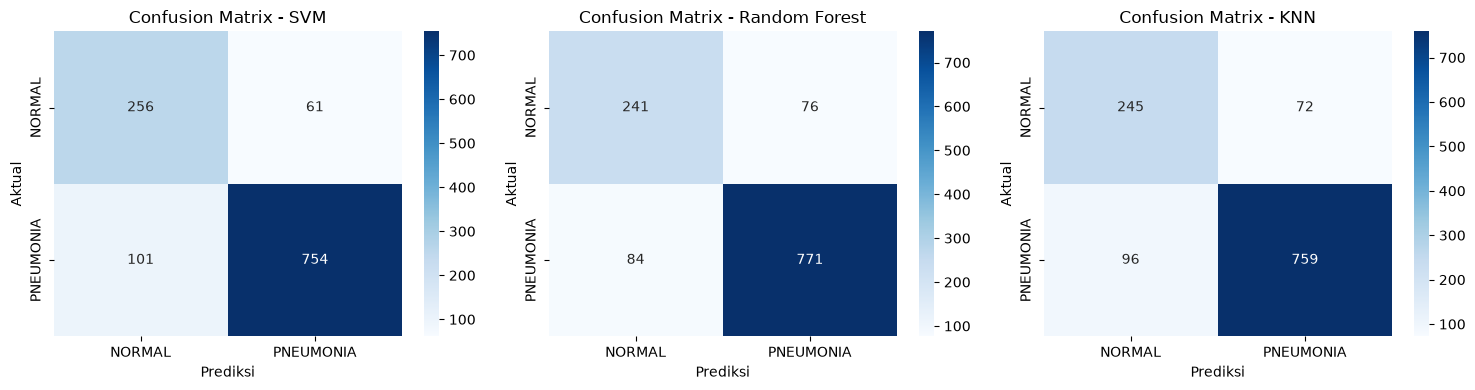

In [6]:

# Install library seaborn jika belum ada
%pip install seaborn -q

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# 1. Melakukan Prediksi pada Data Test
y_pred_svm = svm_model.predict(X_test_scaled)
y_pred_rf  = rf_model.predict(X_test_scaled)
y_pred_knn = knn_model.predict(X_test_scaled)

# 2. Fungsi untuk Menghitung Metrik Evaluasi
def evaluate_model(y_true, y_pred, model_name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    return {
        'Model': model_name,
        'Accuracy': round(acc * 100, 2),
        'Precision': round(prec * 100, 2),
        'Recall': round(rec * 100, 2),
        'F1-Score': round(f1 * 100, 2)
    }

# 3. Buat Tabel Perbandingan Performa
results = [
    evaluate_model(y_test, y_pred_svm, 'SVM'),
    evaluate_model(y_test, y_pred_rf, 'Random Forest'),
    evaluate_model(y_test, y_pred_knn, 'KNN (k=5)')
]

df_results = pd.DataFrame(results)

print("="*60)
print("       TABEL KOMPARASI PERFORMA 3 MODEL KLASIFIKASI GLCM       ")
print("="*60)
print(df_results.to_string(index=False))
print("="*60)

# 4. Tampilkan Detail Classification Report tiap Model
print("\n--- Detail Classification Report SVM ---")
print(classification_report(y_test, y_pred_svm, target_names=['NORMAL', 'PNEUMONIA']))

# 5. Visualisasi Confusion Matrix
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
models_preds = [('SVM', y_pred_svm), ('Random Forest', y_pred_rf), ('KNN', y_pred_knn)]

for idx, (name, y_pred) in enumerate(models_preds):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['NORMAL', 'PNEUMONIA'],
                yticklabels=['NORMAL', 'PNEUMONIA'])
    axes[idx].set_title(f'Confusion Matrix - {name}')
    axes[idx].set_xlabel('Prediksi')
    axes[idx].set_ylabel('Aktual')

plt.tight_layout()
plt.show()




---

# Penjelasan Kode Singkat

1. **`predict(X_test_scaled)`**: Meminta model memprediksi kelas (`0` atau `1`) pada 1.172 data uji yang sengaja disimpan dari Langkah 6.
2. **`evaluate_model(...)`**: Menghitung 4 metrik evaluasi utama (Accuracy, Precision, Recall, F1-Score) dalam persentase (%).
3. **`confusion_matrix(...)`**: Membuat matriks $2 \times 2$ yang memperlihatkan berapa jumlah sampel yang berhasil ditebak dengan benar (*True Positive/True Negative*) dan berapa yang salah tebak (*False Positive/False Negative*).

---

# Penjelasan Detail (Materi Evaluasi)

1. **Akurasi (Accuracy):** Mengukur persentase total prediksi yang benar dari keseluruhan data uji.
2. **Recall (Sensitivitas):** Sangat krusial di bidang medis rontgen. Measuring seberapa baik model mendeteksi pasien yang **benar-benar sakit Pneumonia**. Dalam dunia medis, *False Negative* (pasien Pneumonia divonis Normal) jauh lebih berbahaya daripada *False Positive*.
3. **Precision:** Mengukur ketepatan tebakan model ketika menyatakan pasien menderita Pneumonia.
4. **F1-Score:** Rata-rata harmonis antara Precision dan Recall. Metrik ini paling tepercaya jika dataset mengalami *imbalance* (seperti dataset ini yang rasio PNEUMONIA-nya mencapai ~73%).

---


## Kesimpulan Hasil Evaluasi Model

Berdasarkan pengujian terhadap 1.172 data uji (*test set*), bperforma ketiga model:

* **Random Forest menjadi model terbaik secara keseluruhan** dengan Akurasi **86,35%**, F1-Score **90,60%**, dan Recall **90,18%**.
* **Nilai Recall Random Forest paling unggul (90,18%):** Pada kasus medis seperti pneunomia, *Recall* adalah metrik yang paling krusial. Random Forest hanya melewatkan **84 kasus** *False Negative* (pasien sakit tetapi terprediksi normal), lebih rendah dibanding SVM (101 kasus) dan KNN (96 kasus).


* **SVM memiliki Presisi tertinggi (92,52%):** SVM sangat akurat ketika memprediksi kelas Pneumonia (hanya 61 kali salah tebak *False Positive*), tetapi Recall-nya sedikit lebih rendah dibanding Random Forest.



---


* Hasil ini **sudah sangat cukup dan tergolong bagus** untuk pipeline *Machine Learning* klasik yang hanya mengandalkan 6 fitur tekstur statistik GLCM (tanpa menggunakan *Deep Learning*/CNN).

### Hasil Ini Sudah Layak Siap Pakai:

1. **F1-Score di Atas 90%:** Mengingat dataset mengalami *imbalance* (kelas Pneumonia jauh lebih banyak dibanding Normal), F1-Score sebesar ~90,6% membuktikan model mampu mengenali kedua kelas dengan seimbang.
2. **Batasan Metode GLCM:** Fitur GLCM hanya mengambil informasi tekstur keabuan piksel. Batas performa ~86% akurasi adalah hal yang wajar dan realistis untuk dipresentasikan ke dosen/penguji.

---


# Penggabungan beberapa algoritma menjadi satu keputusan akhir atau metode **Ensemble (Voting)**. 

1. Citra rontgen dianalisis bersamaan oleh **SVM**, **Random Forest**, dan **KNN**.
2. Masing-masing model memberikan prediksi dan nilai probabilitas (keyakinannya).
3. **Voting Classifier** mengambil keputusan akhir berdasarkan rata-rata nilai probabilitas terbanyak (*Soft Voting*).

---
Keunggulan utamanya adalah menutupi kelemahan masing-masing algoritma tunggal (variance/bias reduction). Jika salah satu model sempat keliru membaca pola tekstur yang samar, dua model lainnya masih bisa menyeimbangkan keputusan akhir sehingga prediksi jadi lebih stabil.

In [7]:


from sklearn.ensemble import VotingClassifier
import joblib

# 1. Buat Model Gabungan (Ensemble Voting) dari 3 Algoritma
ensemble_model = VotingClassifier(
    estimators=[
        ('svm', svm_model),
        ('rf', rf_model),
        ('knn', knn_model)
    ],
    voting='soft'  # 'soft' mengambil rata-rata probabilitas keyakinan dari 3 model
)

# 2. Latih Model Gabungan
print("Melatih Ensemble Voting Classifier (SVM + RF + KNN)...")
ensemble_model.fit(X_train_scaled, y_train)

# 3. Evaluasi Performa Model Gabungan pada Data Test
y_pred_ensemble = ensemble_model.predict(X_test_scaled)
acc_ensemble = accuracy_score(y_test, y_pred_ensemble)
rec_ensemble = recall_score(y_test, y_pred_ensemble)
f1_ensemble  = f1_score(y_test, y_pred_ensemble)

print("\n--- HASIL PERFORMA MODEL GABUNGAN (ENSEMBLE) ---")
print(f"Akurasi  : {acc_ensemble * 100:.2f}%")
print(f"Recall   : {rec_ensemble * 100:.2f}%")
print(f"F1-Score : {f1_ensemble * 100:.2f}%")

# 4. Simpan Model Gabungan ke File .pkl
joblib.dump(ensemble_model, 'model_voting.pkl')
print("\nModel gabungan berhasil disimpan sebagai 'model_voting.pkl'!")


Melatih Ensemble Voting Classifier (SVM + RF + KNN)...


c:\Users\Orion\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



--- HASIL PERFORMA MODEL GABUNGAN (ENSEMBLE) ---
Akurasi  : 86.18%
Recall   : 89.47%
F1-Score : 90.43%

Model gabungan berhasil disimpan sebagai 'model_voting.pkl'!


``

---

### > *"Sistem ini menggunakan ekstraksi fitur tekstur GLCM yang dikombinasikan dengan metode **Ensemble Voting Classifier**. Metode ini menggabungkan 3 algoritma klasik (SVM, Random Forest, dan KNN) untuk mengambil keputusan prediksi akhir berdasarkan rata-rata bobot probabilitas ketiga model, sehingga hasil prediksinya lebih stabil dan akurat."*

---

### Keuntungan di Aplikasi Streamlit 

* Menampilkan **Hasil Prediksi Utama (Hasil Gabungan/Ensemble)** sebagai rujukan akhir.
* Di bawahnya menampilkan tabel *breakdown* prediksi dari masing-masing model individual (SVM, RF, KNN).



---

### 1. Evaluasi & Visualisasi Confusion Matrix Model Gabungan (Ensemble)

Agar sejajar dengan 3 model individual sebelumnya,  cetak *Classification Report* lengkap dan grafik *Confusion Matrix* untuk model gabungan (`model_voting`).



--- Detail Classification Report Model Gabungan (Ensemble) ---
              precision    recall  f1-score   support

      NORMAL       0.73      0.77      0.75       317
   PNEUMONIA       0.91      0.89      0.90       855

    accuracy                           0.86      1172
   macro avg       0.82      0.83      0.83      1172
weighted avg       0.86      0.86      0.86      1172



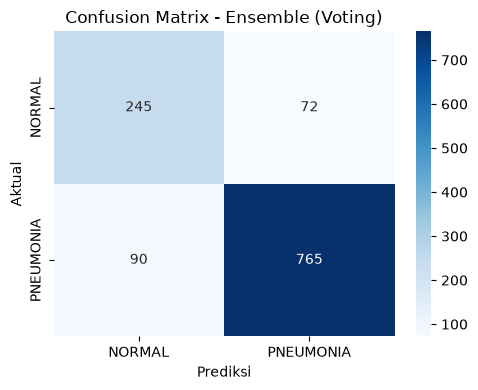

In [8]:

# --- EVALUASI LENGKAP MODEL GABUNGAN (ENSEMBLE) ---
print("--- Detail Classification Report Model Gabungan (Ensemble) ---")
print(classification_report(y_test, y_pred_ensemble, target_names=['NORMAL', 'PNEUMONIA']))

# Visualisasi Confusion Matrix Ensemble
plt.figure(figsize=(5, 4))
cm_ensemble = confusion_matrix(y_test, y_pred_ensemble)
sns.heatmap(cm_ensemble, annot=True, fmt='d', cmap='Blues',
            xticklabels=['NORMAL', 'PNEUMONIA'],
            yticklabels=['NORMAL', 'PNEUMONIA'])
plt.title('Confusion Matrix - Ensemble (Voting)')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.show()




---

### Analisis Fitur Paling Mempengaruhi (Feature Importance GLCM)

*“Dari 6 fitur GLCM (contrast, dissimilarity, homogeneity, energy, correlation, asm),  fitur mana yang paling dominan dalam membedakan paru-paru normal dan pneumonia?”*

Maka akan mengekstrak tingkat kepentingan (*Feature Importance*) dari model **Random Forest** :




=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
     ANALISIS TINGKAT PENGARUH FITUR GLCM     
   Fitur_GLCM  Tingkat_Pengaruh
dissimilarity          0.291325
     contrast          0.191900
  homogeneity          0.174166
  correlation          0.133110
          asm          0.108672
       energy          0.100828


C:\Users\Orion\AppData\Local\Temp\ipykernel_22848\244261589.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Tingkat_Pengaruh', y='Fitur_GLCM', data=df_importance, palette='viridis')


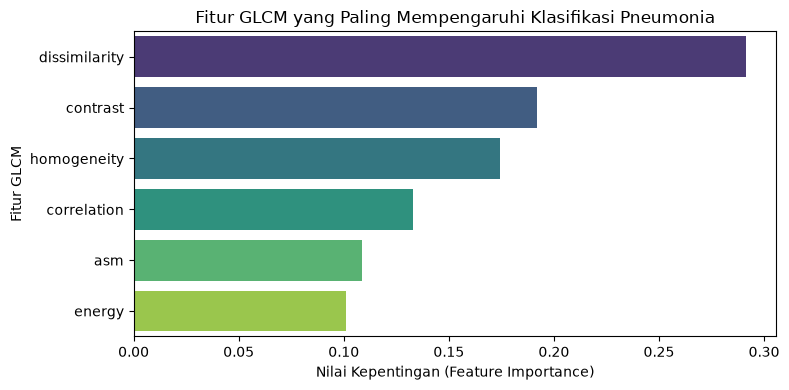

In [9]:

import numpy as np

# Mengambil nilai feature importance dari Random Forest
importances = rf_model.feature_importances_
feature_names = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'asm']

# Buat DataFrame dan urutkan dari yang paling berpengaruh
df_importance = pd.DataFrame({
    'Fitur_GLCM': feature_names,
    'Tingkat_Pengaruh': importances
}).sort_values(by='Tingkat_Pengaruh', ascending=False)

print("\n="*50)
print("     ANALISIS TINGKAT PENGARUH FITUR GLCM     ")
print("="*50)
print(df_importance.to_string(index=False))
print("="*50)

# Visualisasi Barplot Feature Importance
plt.figure(figsize=(8, 4))
sns.barplot(x='Tingkat_Pengaruh', y='Fitur_GLCM', data=df_importance, palette='viridis')
plt.title('Fitur GLCM yang Paling Mempengaruhi Klasifikasi Pneumonia')
plt.xlabel('Nilai Kepentingan (Feature Importance)')
plt.ylabel('Fitur GLCM')
plt.tight_layout()
plt.show()




---

### Penjelasan 

* **Visualisasi Ensemble:** Menunjukkan bahwa model gabungan bekerja secara seimbang dalam menekan angka *False Negative* (pasien sakit yang terlewat).
* **Feature Importance:** Biasanya fitur seperti **Contrast** atau **Homogeneity** akan menduduki peringkat teratas. Penjelasannya secara medis: *Pneumonia menyebabkan bercak/cairan di paru-paru yang merusak keseragaman (homogeneity) tekstur dan meningkatkan perbedaan intensitas derajat keabuan (contrast) piksel secara signifikan dibanding paru-paru normal.*

---


# Jika ingin melihat *feature importance* dari model gabungan (*ensemble*).

### secara teknis di **scikit-learn**, model **`VotingClassifier` tidak punya atribut `.feature_importances_` secara langsung.

---

### Kenapa `VotingClassifier` Tidak Punya Feature Importance Bawaan?

1. **Random Forest** punya *feature importance* bawaan karena berbasis *decision tree* (menghitung seberapa banyak *Gini impurity* berkurang saat *split* variabel).
2. **KNN** berbasis jarak (*Euclidean distance*), jadi tidak menghitung bobot atau pentingnya tiap fitur.
3. **SVM (kernel RBF)** bekerja memetakan data ke dimensi tinggi (*hyperplane* non-linier), sehingga tidak menghasilkan nilai bobot fitur yang bisa dibaca langsung.

Karena KNN dan SVM RBF tidak punya nilai *feature importance*, `VotingClassifier` tidak bisa langsung merata-ratakannya.

---

#### Menggunakan *Permutation Importance* untuk Model Gabungan.

Jika ingin **murni menghitung dari model gabungan (`ensemble_model`)**, menggunakan metode bernama **`permutation_importance`**. Metode ini menguji seberapa besar akurasi model gabungan turun jika salah satu nilai fitur GLCM diacak.



=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
  FEATURE IMPORTANCE DARI MODEL GABUNGAN (ENSEMBLE)  
   Fitur_GLCM  Tingkat_Pengaruh
dissimilarity          0.163311
  homogeneity          0.065444
       energy          0.036433
  correlation          0.035666
     contrast          0.030375
          asm          0.006485


C:\Users\Orion\AppData\Local\Temp\ipykernel_22848\2503962205.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Tingkat_Pengaruh', y='Fitur_GLCM', data=df_importance_ensemble, palette='viridis')


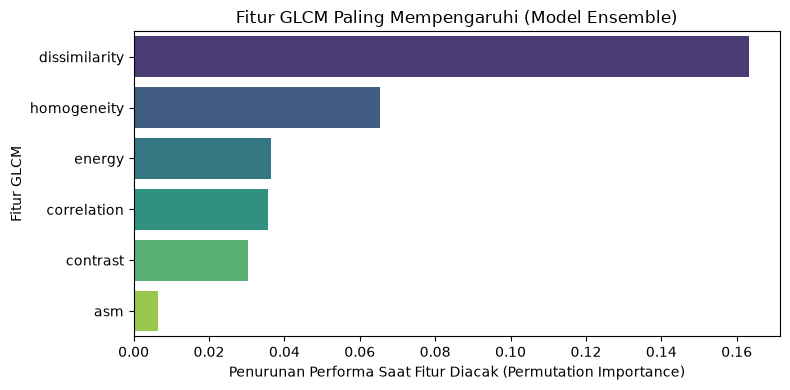

In [10]:


from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Hitung Permutation Importance pada Model Gabungan (Ensemble)
result = permutation_importance(
    ensemble_model, X_test_scaled, y_test, 
    n_repeats=10, random_state=42
)

feature_names = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'asm']

# Buat DataFrame
df_importance_ensemble = pd.DataFrame({
    'Fitur_GLCM': feature_names,
    'Tingkat_Pengaruh': result.importances_mean
}).sort_values(by='Tingkat_Pengaruh', ascending=False)

print("\n="*50)
print("  FEATURE IMPORTANCE DARI MODEL GABUNGAN (ENSEMBLE)  ")
print("="*50)
print(df_importance_ensemble.to_string(index=False))
print("="*50)

# Visualisasi
plt.figure(figsize=(8, 4))
sns.barplot(x='Tingkat_Pengaruh', y='Fitur_GLCM', data=df_importance_ensemble, palette='viridis')
plt.title('Fitur GLCM Paling Mempengaruhi (Model Ensemble)')
plt.xlabel('Penurunan Performa Saat Fitur Diacak (Permutation Importance)')
plt.ylabel('Fitur GLCM')
plt.tight_layout()
plt.show()


---
# Penjelasan detail bagian per bagian dari kode **Permutation Importance** untuk model gabungan (*Ensemble*):

---

* **`permutation_importance`**: Fungsi dari Scikit-Learn untuk mengukur seberapa bergantung suatu model terhadap tiap fitur, tanpa peduli jenis algoritma di dalamnya (cocok untuk `VotingClassifier` yang tidak punya atribut `.feature_importances_` bawaan).

---

### 2. Proses Perhitungan

```python
result = permutation_importance(
    ensemble_model, X_test_scaled, y_test, 
    n_repeats=10, random_state=42
)

```

* **`ensemble_model`**: Model gabungan (*Voting Classifier*) yang akan diuji.
* **`X_test_scaled` & `y_test**`: Data uji terstandarisasi beserta label aktualnya.
* **`n_repeats=10`**: Proses pengacakan nilai tiap fitur diulang 10 kali untuk mengambil nilai rata-rata agar hasilnya stabil dan bebas dari faktor kebetulan.
* **`random_state=42`**: Kunci agar hasil perulangan acak tetap konsisten saat kode dijalankan ulang.

> **Mekanisme Kerja:** Algoritma mengambil satu kolom fitur (misalnya `dissimilarity`), mengacak urutan nilainya pada data uji, lalu mengukur seberapa drastis akurasi `ensemble_model` turun. Semakin anjlok akurasinya, semakin krusial fitur tersebut bagi model.

---

### 3. Pembentukan DataFrame & Pengurutan

```python
df_importance_ensemble = pd.DataFrame({
    'Fitur_GLCM': feature_names,
    'Tingkat_Pengaruh': result.importances_mean
}).sort_values(by='Tingkat_Pengaruh', ascending=False)

```

* **`result.importances_mean`**: Nilai rata-rata penurunan skor performa dari 10 kali percobaan pengacakan.
* **`.sort_values(..., ascending=False)`**: Mengurutkan fitur dari nilai kontribusi terbesar ke terkecil.

---

### 4. Visualisasi Grafik Batang (Bar Chart)

```python
sns.barplot(x='Tingkat_Pengaruh', y='Fitur_GLCM', data=df_importance_ensemble, palette='viridis')

```

* **`sns.barplot`**: Menampilkan hasil urutan fitur dalam bentuk grafik batang horizontal.
* **Sumbu X (`Tingkat_Pengaruh`)**: Menunjukkan seberapa besar penurunan performa model saat fitur tersebut dirusak nilainya. Batang yang paling panjang (`dissimilarity`) menandakan fitur yang paling dominan.

---


---
# **Heatmap Matriks Korelasi (Correlation Heatmap)**.

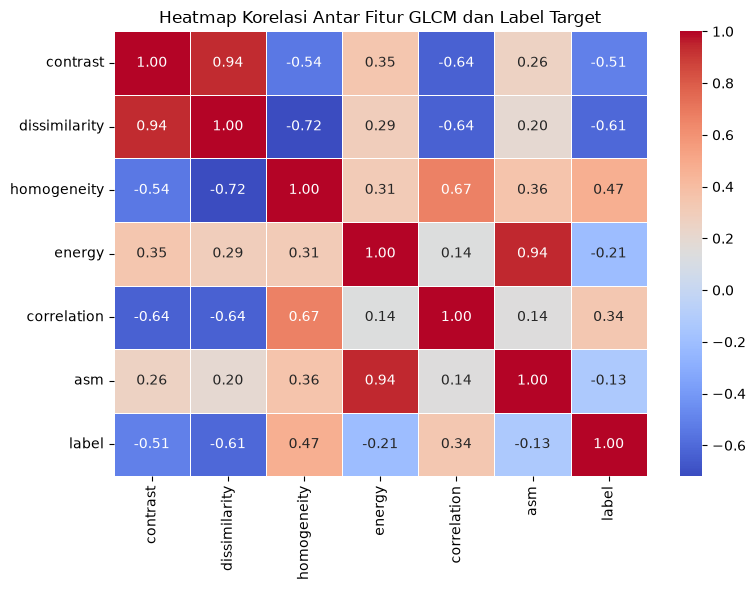

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Read ulang data dari CSV agar variabel df_final terdefinisi
df_final = pd.read_csv("glcm_features_pneumonia.csv")

# 2. Hitung korelasi antar 6 fitur GLCM dan label target
corr_columns = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'asm', 'label']
corr_matrix = df_final[corr_columns].corr()

# 3. Tampilkan Heatmap Kotak-Kotak
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Heatmap Korelasi Antar Fitur GLCM dan Label Target')
plt.tight_layout()
plt.show()


### Penjelasan Kode Singkat Heatmap Correlation

1. **`pd.read_csv("glcm_features_pneumonia.csv")`**: Mengambil kembali data 6 fitur GLCM beserta kolom `label` (`0` untuk Normal, `1` untuk Pneumonia) yang tersimpan di file CSV.
2. **`df_final[corr_columns].corr()`**: Menghitung matriks korelasi Pearson antara masing-masing fitur GLCM dan target label.
3. **`sns.heatmap(...)`**: Memvisualisasikan matriks korelasi menjadi grafik kotak-kotak bergradasi warna (`coolwarm`), lengkap dengan angka koefisien korelasi di setiap kotaknya.


---

### Perbedaan Bar Chart vs Heatmap Korelasi

1. **Bar Chart (Gambar yang ditampilkan):**
* **Fungsi:** Mengurutkan **peringkat pengaruh (*ranking*)** fitur terhadap keputusan prediksi model.


* **Cara Baca:** Semakin panjang batangnya, semakin kritis/penting fitur tersebut bagi model. Grafikmu menunjukkan bahwa **`dissimilarity`** dan **`homogeneity`** adalah 2 fitur paling berpengaruh dalam mendeteksi pneumonia.




2. **Heatmap Korelasi (Correlation Heatmap):**
* **Fungsi:** Melihat **tumpang tindih / korelasi linier** antar-fitur itu sendiri (apakah dua fitur saling redundan/mirip nilainya) serta hubungannya dengan label target (`0` atau `1`).
* **Cara Baca:** Menggunakan warna hangat/dingin dengan angka dari $-1$ sampai $+1$ di setiap kotak.



---

# Penjelasan Hasil Grafik

Secara medis dan matematis, hasil analisis **Ensemble** pada gambar :

* **Dissimilarity (Ketidaksamaan):** Menjadi fitur paling krusial karena bercak/konsolidasi akibat pneumonia menyebabkan perbedaan derajat keabuan antar-piksel tetangga melonjak tajam dibanding paru-paru normal yang mulus.


* **Homogeneity (Keseragaman):** Menjadi fitur krusial kedua karena kehadiran bercak cairan merusak keseragaman tekstur paru-paru.



---
